---
  title: "Aula 5"
  author: Mauro Alixandrini
  date: 2026-16-09
  categories: [GeoAI, technology]
  image: visualizacao.jpg
---

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alixandrini/PPEC083/blob/main/Notebooks/Aula_5.ipynb)

# Criação de Dados de Treinamento

O desempenho de qualquer modelo de GeoAI depende da qualidade e quantidade dos seus dados de treinamento. Erros sutis no georreferenciamento, alinhamento de rótulos ou balanceamento de classes podem se propagar por todo o processo de aprendizagem. Um modelo treinado com pegadas de edificações incompletas irá sistematicamente ignorar estruturas. Um classificador de cobertura do solo treinado com classes desbalanceadas irá ignorar categorias raras. Na prática, a preparação de dados frequentemente consome 60-80% do tempo total do projeto em fluxos de trabalho de GeoAI, e o esforço investido aqui determina diretamente a qualidade dos resultados finais.

# O Pipeline de Dados de Treinamento

Criar dados de treinamento para GeoAI é um processo de múltiplas etapas que transforma dados geoespaciais brutos no formato estruturado que frameworks de deep learning esperam. O pipeline segue um padrão consistente independentemente da tarefa específica (segmentação, detecção ou classificação):

1. **Adquirir imagens e rótulos**: Obter imagens de satélite ou aéreas junto com anotações correspondentes como pegadas de edificações, polígonos de cobertura do solo ou caixas delimitadoras de objetos.
2. **Converter rótulos vetoriais em máscaras raster**: Rasterizar anotações vetoriais em uma grade que corresponda à resolução e sistema de referência de coordenadas das imagens.
3. **Dividir as imagens em tiles**: Fatiar grandes cenas raster em chips de imagem de tamanho fixo que cabem na memória da GPU e correspondam às dimensões de entrada esperadas pelas redes neurais.
4. **Gerar rótulos emparelhados**: Para cada chip de imagem, produzir o tile de rótulo correspondente (máscara raster para segmentação ou arquivo de caixa delimitadora para detecção).
5. **Visualizar e validar**: Inspecionar os tiles gerados para verifi car alinhamento e qualidade dos rótulos antes do treinamento.
6. **Dividir em subconjuntos**: Dividir o dataset em conjuntos de treinamento, validação e teste, tomando cuidado para manter a separação espacial.

## Gerando Chips de Imagem a Partir de uma Única Imagem
Cenas de imagens de satélite e aéreas são grandes demais para alimentar diretamente uma rede neural.


Uma única cena NAIP pode ter dezenas de milhares de pixels em cada lado, enquanto a maioria dos modelos de deep learning espera entradas de 256 x 256 ou 512 x 512 pixels. Tiling (ou “chipping”) é o processo de fatiar essas grandes cenas em pedaços gerenciáveis.
### Download de Dados de Exemplo
Começamos baixando uma imagem NAIP de exemplo e suas anotações de pegadas de edifi cações correspondentes. A imagem NAIP cobre uma pequena área e o arquivo vetorial contém polígonos de edificações digitalizados a partir das imagens.


In [1]:
import geoai
raster_url = "https://data.source.coop/opengeos/geoai/naip-train.tif"
vector_url = "https://data.source.coop/opengeos/geoai/naip-train-buildings.geojson"
raster_path = geoai.download_file(raster_url)
vector_path = geoai.download_file(vector_url)

### Pré-visualizar Dados

Antes  de  gerar  chips,  sempre  inspecione  as  imagens  de  origem  e  anotações  visualmente.
Esta etapa detecta problemas como rótulos desalinhados, configurações de CRS incorretas ou artefatos inesperados na imagem antes que se propaguem para o dataset de treinamento.

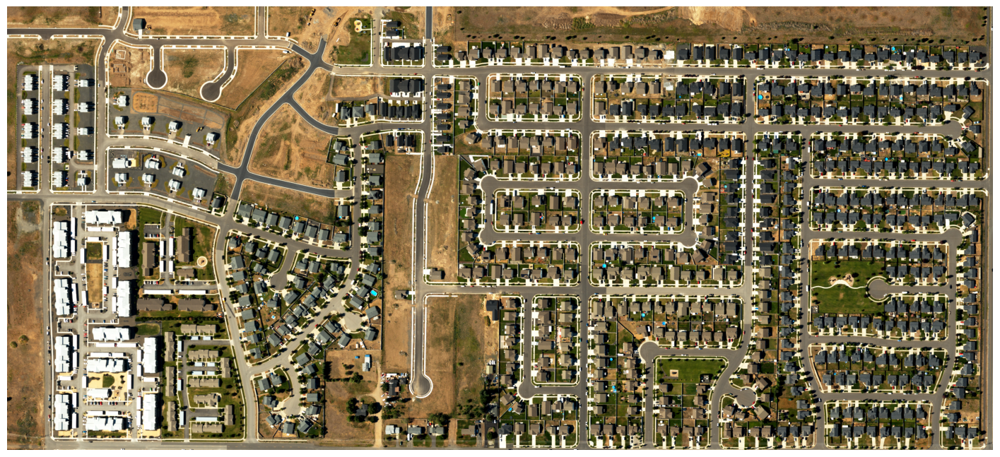

<Axes: >

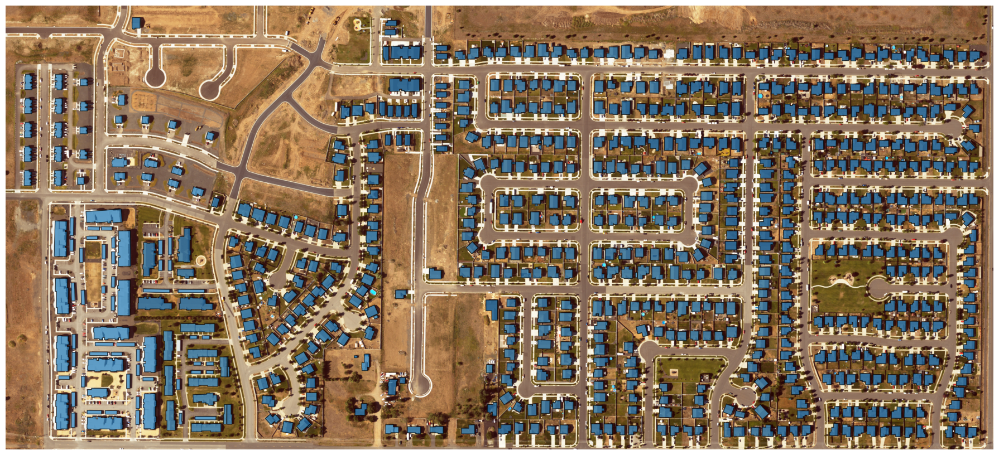

In [3]:
geoai.view_image(raster_path, figsize=(18, 10))
geoai.view_vector(vector_path, raster_path=raster_path, figsize=(18, 10))

In [ ]:
geoai.view_vector_interactive(vector_path, tiles=raster_path)

### Converter Vetor em Raster
Modelos de segmentação semântica requerem rótulos no nível de pixel, onde cada pixel na imagem de rótulo recebe um valor de classe. A função  ```vector_to_raster()```  rasteriza polígonos vetoriais em uma grade que corresponde à resolução, extensão e CRS do raster de referência. Isso produz uma máscara binária onde pixels de edificação têm valor 1 e pixels de fundo têm valor 0 

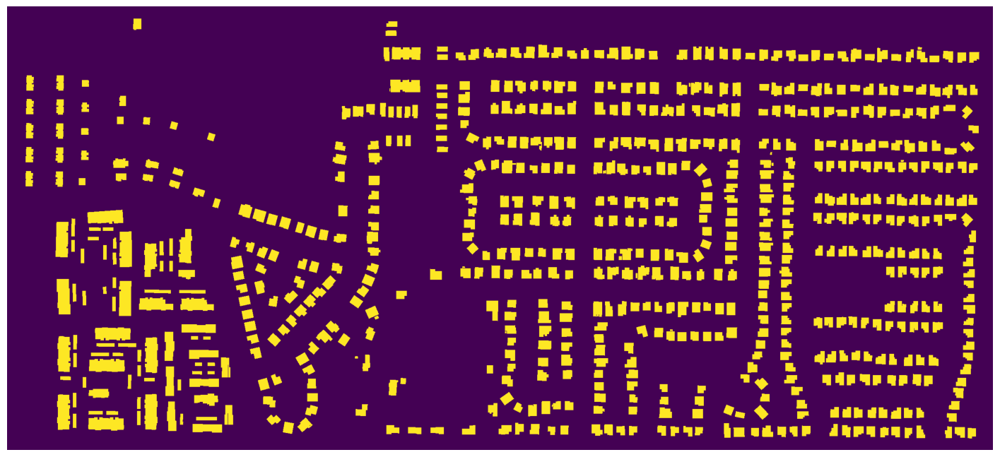

In [5]:
output_path = vector_path.replace(".geojson", ".tif")
geoai.vector_to_raster(vector_path, output_path, reference_raster=raster_path)
geoai.view_image(output_path, figsize=(18, 10))

### Parâmetros de Tiling

Os parâmetros principais para geração de chips são:

* **Tamanho do tile**: A largura e altura de cada chip em pixels (por exemplo, 256 x 256 ou 512 x 512). Deve corresponder ao tamanho de entrada que seu modelo espera.
* **Stride**: O tamanho do passo entre chips consecutivos. Quando o stride é igual ao tamanho do tile, os chips não se sobrepõem. Quando o stride é menor, os chips se sobrepõem.


Tiles sem sobreposição podem criar problemas nas bordas dos chips. Objetos que cruzam a borda entre dois chips são divididos, deixando feições incompletas em ambos os chips. Isso é especialmente problemático para detecção de edificações e extração de estradas, onde objetos truncados confundem o modelo durante o treinamento.


Tiles com sobreposição resolvem isso garantindo que objetos nas bordas apareçam completamente em pelo menos um chip. Proporções comuns de sobreposição incluem:


|Sobreposição |Stride (para tiles de 256px)| Stride (para tiles de 512px)| Caso de Uso|
|-----|-----|-----|-----|
|0% | 256| 512| Classificação  simples, grandes áreas uniformes|
|25% | 192| 384| Uso geral, objetos moderados nas bordas|
|50% | 128| 256| Detecção  densa  de  objetos, pegadas de edificações|
|75% | 64| 128| Cobertura máxima, detecção de objetos pequenos|


Maior  sobreposição  produz  mais  chips,  o  que  aumenta  os  requisitos  de  armazenamento  e  tempo  de processamento. Uma sobreposição de 50% quadruplica o número de chips em comparação com nenhuma sobreposição. Escolha a sobreposição com base nos tamanhos dos seus objetos em relação às dimensões do tile e no seu orçamento computacional.

###   Gerar Tiles
A função  ```export_geotiff_tiles()```  lida com o fluxo de trabalho completo de geração de chips: divisão de imagens em tiles, rasterização de rótulos vetoriais em máscaras e salvamento de pares de tiles imagem-máscara. O parâmetro  ```create_overview```  gera uma única imagem de visão geral mostrando todos os limites dos tiles, o que é útil para verificar a cobertura espacial.


In [6]:
tiles = geoai.export_geotiff_tiles(
    in_raster=raster_path,
    out_folder="output",
    in_class_data=vector_path,
    tile_size=512,
    stride=384,
    buffer_radius=0,
     create_overview=True,
    quiet=True,
)

### Pré-visualizar Chips de Imagem
Após gerar tiles, inspecione a visão geral e pares individuais de imagem-máscara para verificar se os rótulos estão corretamente alinhados com as feições nas imagens. Cada tile de imagem deve ter um tile de máscara correspondente com extensão espacial correspondente.

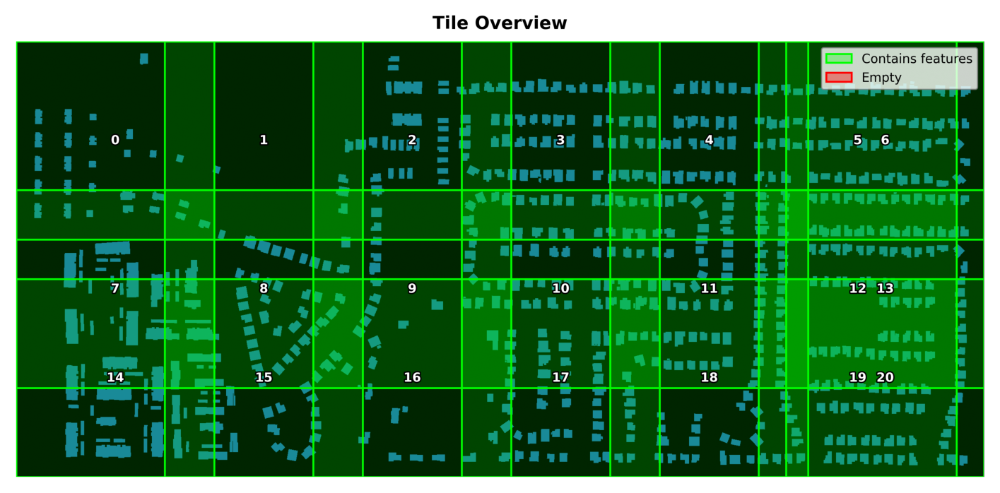

In [7]:
geoai.view_image("output/overview.png", figsize=(18, 10))

Para visualizar os tiles gerados, use a função  ```display_training_tiles()```  

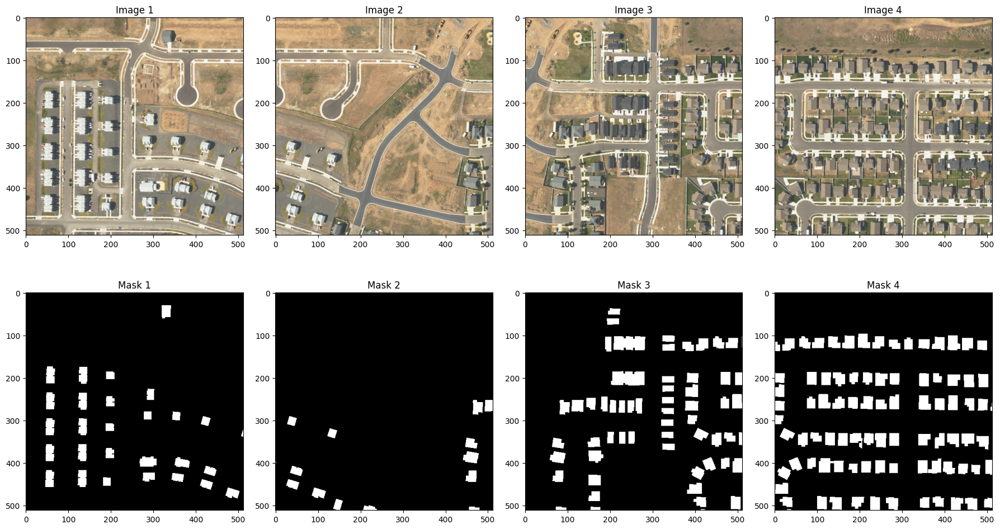

In [8]:
fig = geoai.display_training_tiles(output_dir="output", num_tiles=4, figsize=(18,10))

### Processamento em Lote de Múltiplas Imagens
Em projetos do mundo real, os dados de treinamento frequentemente abrangem múltiplas cenas de satélite ou tiles de imagem. A função  ```export_geotiff_tiles_batch()```  lida com processamento em lote de pastas de imagens e suporta três modos diferentes para emparelhar imagens com suas anotações:
1. Arquivo vetorial único cobrindo todas as imagens - Mais eficiente quando você tem um grande arquivo de anotação
2. Múltiplos arquivos vetoriais emparelhados por ordem de classificação  - Bom para datasets sequenciais
3. Múltiplos arquivos vetoriais emparelhados por nome de arquivo - Bom para datasets emparelhados com nomes correspondentes

### Download de Dados de Exemplo em Lote
O dataset de exemplo contém dois tiles de imagem NAIP junto com anotações de edifi cações em dois
formatos: um único arquivo GeoJSON cobrindo ambos os tiles e arquivos GeoJSON separados para cada

In [9]:
import os
url = "https://data.source.coop/opengeos/geoai/naip-rgb-train-tiles.zip"
data_dir = geoai.download_file(url)

### Explorar Dados de Exemplo
Vamos listar os arquivos no diretório de dados de exemplo para ver o que está incluído:

In [10]:
print("Images:")
for f in sorted(os.listdir(f"{data_dir}/images")):
    print(f"  - {f}")
print("\nAnnotations (single file):")
for f in sorted(os.listdir(f"{data_dir}/masks1")):
    print(f"  - {f}")
print("\nAnnotations (multiple files):")
for f in sorted(os.listdir(f"{data_dir}/masks2")):
    print(f"  - {f}")

Images:
  - naip_rgb_train_tile1.tif
  - naip_rgb_train_tile2.tif

Annotations (single file):
  - naip_train_buildings.geojson

Annotations (multiple files):
  - naip_rgb_train_tile1.geojson
  - naip_rgb_train_tile2.geojson


### Visualizar Imagem e Anotações
A  função  ```display_image_with_vector()```   sobrepõe  anotações  vetoriais  na  imagem  de  origem, fornecendo uma verificação visual rápida do alinhamento dos rótulos.

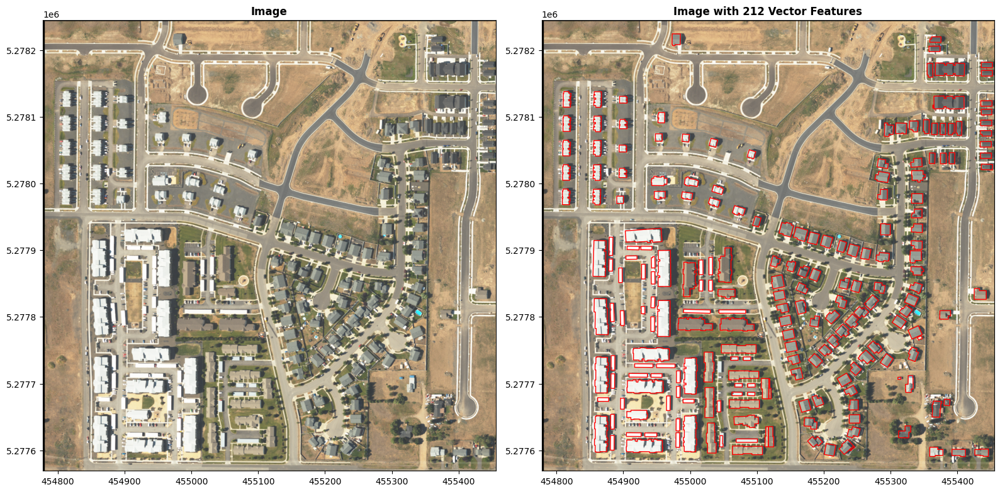

Number of buildings: 212


In [11]:
image_path = f"{data_dir}/images/naip_rgb_train_tile1.tif"
mask_path = f"{data_dir}/masks2/naip_rgb_train_tile1.geojson"
fig, axes, info = geoai.display_image_with_vector(image_path, mask_path)
print(f"Number of buildings: {info['num_features']}")

### Método 1: Arquivo Vetorial Único Cobrindo Todas as Imagens
Este é o método mais eficiente quando você tem um grande arquivo de anotação cobrindo múltiplos tiles de imagem. A função carrega o arquivo vetorial uma vez, filtra espacialmente as feições para cada imagem com base em seus limites e, com  ```skip_empty_tiles=True``` , gera tiles apenas onde feições existem.

In [12]:
stats = geoai.export_geotiff_tiles_batch(
    images_folder=f"{data_dir}/images",
    masks_file=f"{data_dir}/masks1/naip_train_buildings.geojson",
    output_folder="output/method1_single_mask",
    tile_size=256,
    stride=128,
    class_value_field="class",
    skip_empty_tiles=True,
    quiet=False,
)
print(f"\n{'='*60}")
print("Results:")
print(f"  Images processed: {stats['processed_pairs']}")
print(f"  Total tiles generated: {stats['total_tiles']}")
print(f"  Tiles with features: {stats['tiles_with_features']}")
print(f"  Feature percentage: {stats['tiles_with_features']/
stats['total_tiles']*100:.1f}%")

Processing image pairs:   0%|          | 0/2 [00:00<?, ?it/s]


Results:
  Images processed: 2
  Total tiles generated: 141
  Tiles with features: 141
  Feature percentage: 100.0%


### Método 2: Múltiplos Arquivos Vetoriais Emparelhados por Ordem de Classificação
Este  método  emparelha  imagens  e  máscaras  alfabeticamente  por  ordem  de  classificação.  A  primeira imagem é emparelhada com a primeira máscara, a segunda com a segunda, e assim por diante. Isso é útil quando seus arquivos seguem uma convenção de ordenação consistente, mas os nomes base não correspondem exatamente. Use este modo apenas quando estiver confi ante de que as listas de arquivos classificadas se alinham corretamente.

In [13]:
stats = geoai.export_geotiff_tiles_batch(
    images_folder=f"{data_dir}/images",
    masks_folder=f"{data_dir}/masks2",
    output_folder="output/method2_sorted_order",
    tile_size=256,
    stride=128,
    class_value_field="class",
    skip_empty_tiles=True,
    match_by_name=False,
)
print(f"\n{'='*60}")
print("Results:")
print(f"  Images processed: {stats['processed_pairs']}")
print(f"  Total tiles generated: {stats['total_tiles']}")
print(f"  Tiles with features: {stats['tiles_with_features']}")

Processing image pairs:   0%|          | 0/2 [00:00<?, ?it/s]


Results:
  Images processed: 2
  Total tiles generated: 141
  Tiles with features: 141


### Método 3: Múltiplos Arquivos Vetoriais Emparelhados por Nome de Arquivo
Este método emparelha imagens e máscaras correspondendo seus nomes base de arquivo (por exemplo, ```tile1.tif```  é emparelhado com  ```tile1.geojson``` ). É a opção mais segura quando imagens e máscaras compartilham o mesmo nome base, mas usam extensões diferentes.

In [14]:
stats = geoai.export_geotiff_tiles_batch(
    images_folder=f"{data_dir}/images",
    masks_folder=f"{data_dir}/masks2",
    output_folder="output/method3_matched_name",
    tile_size=256,
    stride=128,
    class_value_field="class",
    skip_empty_tiles=True,
    match_by_name=True,
)
print(f"\n{'='*60}")
print("Results:")
print(f"  Images processed: {stats['processed_pairs']}")
print(f"  Total tiles generated: {stats['total_tiles']}")
print(f"  Tiles with features: {stats['tiles_with_features']}")

Processing image pairs:   0%|          | 0/2 [00:00<?, ?it/s]


Results:
  Images processed: 2
  Total tiles generated: 141
  Tiles with features: 141


### Visualizar Tiles Gerados
A função  ```display_training_tiles()```  mostra uma grade de pares imagem-máscara de um diretório de saída, fornecendo uma visão geral rápida dos dados de treinamento gerados.

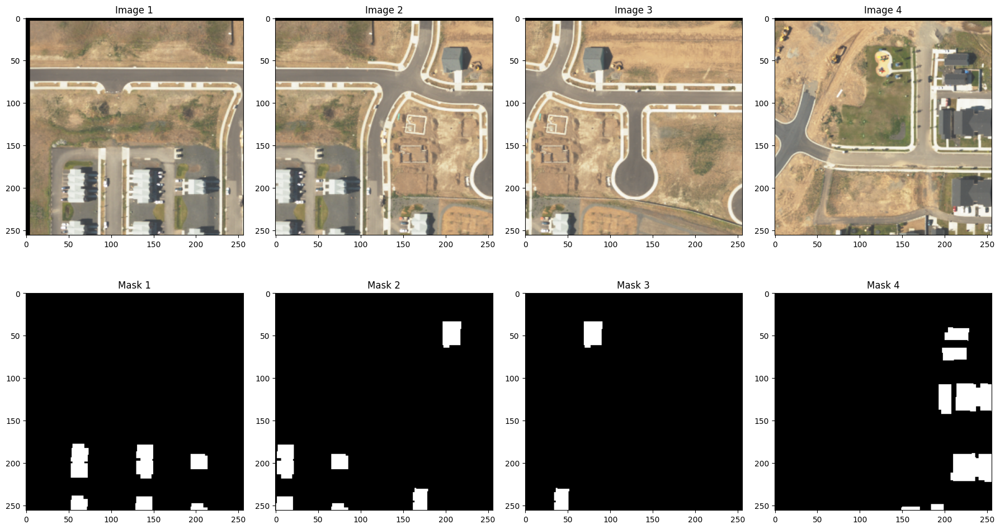

In [15]:
output_dir = "output/method1_single_mask"
fig = geoai.display_training_tiles(output_dir, num_tiles=4, figsize=(18, 10))

### Uso Avançado: Parâmetros Personalizados
A função  ```export_geotiff_tiles_batch()```  suporta muitos parâmetros para personalização, incluindo tamanho do tile, stride (sobreposição), raio de buffer ao redor de feições, filtragem de tiles vazios e mais.

In [16]:
stats = geoai.export_geotiff_tiles_batch(
    images_folder=f"{data_dir}/images",
    masks_file=f"{data_dir}/masks1/naip_train_buildings.geojson",
    output_folder="output/advanced_example",
    tile_size=512,
    stride=256,
    class_value_field="class",
    buffer_radius=0.5,
    skip_empty_tiles=True,
    all_touched=True,
    max_tiles=10,
    quiet=False,
)
print(f"\nGenerated {stats['total_tiles']} tiles with 50% overlap")
print(f"Output structure:")
print(f"  - output/advanced_example/images/  (image tiles)")
print(f"  - output/advanced_example/masks/   (mask tiles)")

Processing image pairs:   0%|          | 0/2 [00:00<?, ?it/s]


Generated 20 tiles with 50% overlap
Output structure:
  - output/advanced_example/images/  (image tiles)
  - output/advanced_example/masks/   (mask tiles)


### Processamento em Lote com Máscaras Raster
Quando suas anotações já estão rasterizadas, como mapas de classificação de cobertura do solo, você pode passar uma pasta de máscaras raster diretamente em vez de arquivos vetoriais. Esse fluxo de trabalho é comum em tarefas de segmentação de cobertura do solo onde os rótulos já estão armazenados como imagens raster classificadas. O exemplo a seguir baixa um dataset de cobertura do solo de exemplo e o processa com  export_```geotiff_tiles_batch()``` .

In [17]:
url = "https://data.source.coop/opengeos/geoai/landcover-sample-data.zip"
data_dir2 = geoai.download_file(url)
images_dir = f"{data_dir2}/images"
masks_dir = f"{data_dir2}/masks"
tiles_dir = f"{data_dir2}/tiles"
result = geoai.export_geotiff_tiles_batch(
    images_folder=images_dir,
    masks_folder=masks_dir,
    output_folder=tiles_dir,
    tile_size=512,
    stride=384,
    quiet=True,
)

Os tiles gerados são armazenados na pasta de saída com duas subpastas:  images/  e  masks/ . Cada tile de imagem tem um tile de máscara correspondente com extensão espacial correspondente, pronto para treinar um modelo de segmentação.

##  Considerações sobre Qualidade dos Rótulos
Rótulos de alta qualidade são essenciais para o desempenho do modelo. Problemas comuns a observar incluem:
* **Anotações incompletas**: Objetos ausentes nos dados de treinamento ensinam o modelo a ignorar esses objetos. Garanta que todas as instâncias das suas classes alvo estejam rotuladas dentro de cada chip.
* **Desalinhamento  espacial**:  Rótulos  que  não  se  alinham  precisamente  com  as  imagens  (devido  a incompatibilidades de CRS ou erros de digitalização) introduzem ruído. Sempre verifique se as anotações vetoriais se sobrepõem corretamente ao raster usando  ```display_image_with_vector()``` .
* **Desbalanceamento de classes**: Quando uma classe domina o dataset (por exemplo, pixels de fundo superam vastamente pixels de edificação), o modelo pode aprender a predizer exclusivamente a classe majoritária. Acompanhe distribuições de classes e considere estratégias como sobreamostragem, ponderação de classes ou focal loss.
* **Efeitos de borda**: Objetos nas bordas dos chips podem estar parcialmente rotulados. A estratégia de sobreposição descrita anteriormente mitiga este problema. O parâmetro  ```skip_empty_tiles```  também ajuda ao excluir tiles sem feições.
* **Raio  de  buffer** :  Adicionar  um  pequeno  buffer  ao  redor  de  feições  vetoriais  (usando  o  parâmetro ```buffer_radius``` ) pode compensar leve desalinhamento entre imagens e anotações.
##  Organização do Dataset
###  Divisões Treinamento/Validação/Teste
Dividir dados em conjuntos de treinamento, validação e teste segue os mesmos princípios do aprendizado de máquina geral, com uma adição crítica: separação espacial. Em dados geoespaciais, chips próximos são altamente correlacionados porque compartilham a mesma paisagem, condições de iluminação e estado sazonal. Se chips de treinamento e validação vêm de locais adjacentes na mesma cena, o modelo pode alcançar pontuações de validação artifi cialmente altas memorizando padrões espaciais em vez de aprender feições generalizáveis. Esse problema é frequentemente descrito como autocorrelação espacial levando a vazamento de dados.


Para evitar vazamento, divida os dados no nível de cena ou região em vez do nível de chip:
* **Divisão baseada em região**: Atribua regiões geográfi cas inteiras a diferentes divisões. Por exemplo, use imagens de uma cidade para treinamento, outra para validação e uma terceira para teste.
* **Divisão baseada em cena**: Se trabalhando com múltiplas cenas de satélite, atribua cenas inteiras a diferentes divisões.
* **Buffer espacial**: Ao dividir dentro de uma única cena, deixe uma zona de buffer (várias larguras de chip) entre áreas de treinamento e validação.
Proporções comuns de divisão são 70/15/15 ou 80/10/10 para conjuntos de treinamento, validação e teste.

### Estrutura de Diretórios
A maioria dos frameworks de deep learning espera dados de treinamento organizados em um layout de diretórios específi co. O pacote  geoai  gera a seguinte estrutura:
Datasets de segmentação (pares imagem-máscara):
```
dataset/
    images/
        tile_000000.tif
        tile_000001.tif
        ...
    masks/
        tile_000000.tif
        tile_000001.tif
        ...
```

Para projetos que requerem pastas separadas de treinamento/validação/teste, organize os tiles em subdi retórios:
```
dataset/
    train/
        images/
        masks/
    val/
        images/
        masks/
    test/
        images/
        masks/
```

Datasets de detecção (formato YOLO):
```
dataset/
    images/
        train/
            chip_0001.tif
        val/
            chip_0001.tif
    labels/
        train/
            chip_0001.txt
        val/
            chip_0001.txt
    data.yaml
```
Consistência na nomenclatura entre arquivos de imagem e rótulo (nomes de arquivo correspondentes com extensões diferentes ou nomes de arquivo idênticos em diretórios paralelos) é essencial para que os data loaders os emparelhem corretamente.

## Exercício 1: Gerar Chips de Imagem com Diferentes Configurações de Sobreposição
Usando as imagens NAIP de exemplo deste capítulo, gere chips de imagem com três configurações diferentes de sobreposição: 0% (stride=512), 25% (stride=384) e 50% (stride=256) usando um tamanho de tile de 512. Compare o número total de chips produzidos em cada caso. Examine alguns chips de cada conjunto perto das bordas da imagem e note como pegadas de edificações nas bordas dos tiles são tratadas de forma diferente.

## Exercício 2 Preparar um Dataset de Treinamento Completo
Combine  as  técnicas  deste  capítulo  em  um  pipeline  completo.  Começando  com  as  imagens  CBERS, (1) gere chips de 256 x 256 com 50% de sobreposição, (2) crie rótulos de máscara raster a partir de pegadas de edificações e (3) organize os dados em conjuntos espacialmente separados de treinamento (70%), validação (15%) e teste (15%).